# Retrieval Comparison with SQuAD-Benchmark

This notebook compares different embedding and reranking approaches on the SQuAD dataset with paragraphs as chunks.  
Models are given in the settings cell as a list of local or OpenRouter models.

In [ ]:
import os
import json

import time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import bm25s
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from datasets import load_dataset
from dotenv import load_dotenv
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings
from tqdm.auto import tqdm

load_dotenv()

True

## Settings and Models

Each model is a dict with `name` (used for plots and index folders), `provider` (`"local"` or `"openrouter"`) and `model` (Hugging Face or OpenRouter ID). Personally, I used Kaggle Notebooks to run the local models in an acceptable amount of time and would recommend it if you also don't have much compute and patience available :)  
Deactivate a model by commenting out its line.

In [ ]:
DEVICE = "cpu"
EVAL_SPLIT = "train"   # tune on train, evaluate on validation
N_EVAL = 1500             # number of queries to evaluate

K_VALUES = (1, 5, 10, 20)
KMAX = max(K_VALUES)
SEED = 42

DEPTH = 100                 # candidate depth for BM25 and Dense retrieval before fusion
RRF_WEIGHTS = [1.0, 1.0]    # [BM25, Dense]
TOP_N = 20                  # number of candidates to rerank (<= DEPTH)
CAND_DEPTH = max(TOP_N, KMAX) 
RERANK_BASE = None          # name of the embedding model for which the hybrid-candidates are used for reranking (None = first one in list)

INDEX_ROOT = "indexes"      # FAISS index per embedding model (to embed only once)
CACHE_ROOT = "cache"        # cached OpenRouter rerank results (to avoid repeated reranking of the same candidates)
OPENROUTER_BASE = "https://openrouter.ai/api/v1"
OPENROUTER_WORKERS = 4      # parallel rerank requests
EMBED_BATCH = {"openrouter": 100, "local": 256}

QWEN_PREFIX = "Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery: "
BGE_PREFIX = "Represent this sentence for searching relevant passages: "

EMBEDDING_MODELS = [
    dict(name="qwen3-8b",  provider="openrouter", model="qwen/qwen3-embedding-8b", query_prefix=QWEN_PREFIX),
    dict(name="bge-m3", provider="openrouter",      model="baai/bge-m3",  query_prefix=BGE_PREFIX),
    dict(name="voyage-4-large",provider="openrouter", model="voyageai/voyage-4-large"),
    dict(name="oai-3-large",   provider="openrouter", model="openai/text-embedding-3-large"),
    dict(name="qwen3-4b", provider="openrouter", model="qwen/qwen3-embedding-4b", query_prefix=QWEN_PREFIX),
    #dict(name="e5-small", provider="local", model="intfloat/e5-small-v2", query_prefix="query: ", doc_prefix="passage: "),
]

RERANKERS = [
    dict(name="cohere-3.5", provider="openrouter", model="cohere/rerank-v3.5"),
    dict(name="voyage-3-lite", provider="openrouter", model="voyageai/rerank-3-lite"),
    dict(name="qwen3-reranker-8b", provider="openrouter", model="qwen/qwen3-reranker-8b")
    #dict(name="minilm-l6",  provider="local",      model="cross-encoder/ms-marco-MiniLM-L-6-v2"),
    #dict(name="mxbai-xsmal", provider="local", model="mixedbread-ai/mxbai-rerank-xsmall-v1"),
]

os.makedirs(INDEX_ROOT, exist_ok=True)
os.makedirs(CACHE_ROOT, exist_ok=True)
BASE_CONFIG = {"unit": "paragraph", "split": EVAL_SPLIT, "n": N_EVAL, "seed": SEED}

## Data Preperation

We load SQuAD and build the corpus. Every unique paragraph from train and validation is added
exactly once as a document (overall about 21,000), prefixed with its article title and assigned an ID
(`pid`).  
Since SQuAD has one row per question, the same paragraph appears multiple times. `pid_of`
ensures it is only added on its first occurrence.

We then draw a fixed-seed sample of questions from `EVAL_SPLIT`.  
For each question we store the `pid` of the paragraph it was asked about (`gold_pids`) and the article title (`gold_titles`).  
A retrieval counts as a hit if exactly this paragraph is found. The title lets us investigate if at least
the right article was retrieved.

In [ ]:
ds = load_dataset("rajpurkar/squad")

pid_of = {}
docs = []

for split in ("train", "validation"):
    for title, ctx in zip(ds[split]["title"], ds[split]["context"]):
        if ctx not in pid_of:
            pid = len(docs)
            pid_of[ctx] = pid
            content = f"{title.replace('_', ' ')}\n{ctx}"
            docs.append(Document(page_content=content, metadata={"pid": pid, "title": title}))
doc_texts = [d.page_content for d in docs]
print(f"{len(docs)} paragraphs loaded from SQuAD dataset")



sample = ds[EVAL_SPLIT].shuffle(seed=SEED).select(range(N_EVAL))
questions = sample["question"]
qids = sample["id"]
gold_pids = [pid_of[c] for c in sample["context"]]
gold_titles = sample["title"]

20958 paragraphs loaded from SQuAD dataset


## Helper-Functions for Embeddings

In [ ]:
def make_embeddings(cfg):
    """Create an embedding model based on the given configuration."""
    if cfg["provider"] == "openrouter":
        return OpenAIEmbeddings(
            model=cfg["model"],
            base_url=OPENROUTER_BASE,
            api_key=os.environ["OPENROUTER_API_KEY"],
            check_embedding_ctx_length=False,
            chunk_size=EMBED_BATCH["openrouter"],
            max_retries=5,
        )
    if cfg["provider"] == "local":
        from langchain_huggingface import HuggingFaceEmbeddings
        return HuggingFaceEmbeddings(
            model_name=cfg["model"],
            model_kwargs={"device": DEVICE},
            encode_kwargs={"normalize_embeddings": True, "batch_size": 32},
        )
    raise ValueError(f"Unknown provider: {cfg['provider']}")


def embed_texts(emb, texts, batch_size, desc):
    """Batchwhise embedding of texts with normalization of the resulting vectors."""
    out = []
    with tqdm(total=len(texts), desc=desc, unit="text") as bar:
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            out.append(np.asarray(emb.embed_documents(batch), dtype="float32"))
            bar.update(len(batch))
    X = np.vstack(out)
    faiss.normalize_L2(X)
    return X


def load_or_build_index(cfg, emb):
    """Load an existing FAISS index or build a new one based on the given configuration."""
    path = os.path.join(INDEX_ROOT, cfg["name"])
    if os.path.exists(path):
        vs = FAISS.load_local(path, emb, allow_dangerous_deserialization=True)
        print(f"Index loaded: {path}")
    else:
        prefix = cfg.get("doc_prefix", "")
        print(f"Building index: {path}")
        X = embed_texts(emb, [prefix + t for t in doc_texts], EMBED_BATCH[cfg["provider"]],
                        desc=f"Embed Corpus ({cfg['name']})")
        vs = FAISS.from_embeddings(list(zip(doc_texts, X)), emb,
                                   metadatas=[d.metadata for d in docs])
        vs.save_local(path)
        print(f"Index saved: {path}")
    return vs

## Helper Functions: Fusion, Evaluation, Plot

In [ ]:
def rrf(rankings, weights=None, k=60):
    """Reciprocal Rank Fusion (RRF) for combining multiple ranked lists into a single ranking (here: BM25 and Dense retrieval results)."""
    weights = weights or [1.0] * len(rankings)
    scores = defaultdict(float)
    for w, ranking in zip(weights, rankings):
        for rank, doc_id in enumerate(ranking):
            if doc_id != -1:
                scores[int(doc_id)] += w / (k + rank + 1)
    return sorted(scores, key=scores.get, reverse=True)


def evaluate(id_lists, method, config=None, out_file="results.jsonl"):
    """Evaluate the performance of a retrieval method."""
    ranks, categories = [], defaultdict(int)
    for ids, gold_pid, gold_title in zip(id_lists, gold_pids, gold_titles):
        retrieved = [docs[int(i)] for i in list(ids)[:KMAX] if i != -1]  # get the top KMAX retrieved documents
        rank = next((r for r, d in enumerate(retrieved) if d.metadata["pid"] == gold_pid), None) # find the rank of the gold document
        ranks.append(rank)
        if rank is not None:
            categories["hit"] += 1
        elif any(d.metadata["title"] == gold_title for d in retrieved):
            categories["right article, wrong paragraph"] += 1
        else:
            categories["wrong article"] += 1

    n = len(ranks)
    results = {
        "method": method,
        "config": {**BASE_CONFIG, **(config or {})},
        "n": n,
        **{f"recall@{k}": float(np.mean([r is not None and r < k for r in ranks])) for k in K_VALUES},
        f"mrr@{KMAX}": float(np.mean([1 / (r + 1) if r is not None else 0 for r in ranks])),
        f"errors@{KMAX}": {c: cnt / n for c, cnt in categories.items()},
    }
    summary = "  ".join(f"R@{k}={results[f'recall@{k}']:.3f}" for k in K_VALUES)
    print(f"{method:<32} {summary}  MRR={results[f'mrr@{KMAX}']:.3f}")

    with open(out_file, "a", encoding="utf-8") as f:
        f.write(json.dumps(results) + "\n")
    return results, ranks


def plot_bars(results, title, metrics=None):
    """Grouped bar plot: metrics on the x-axis, one bar per method."""
    metrics = metrics or [f"recall@{k}" for k in K_VALUES] + [f"mrr@{KMAX}"]
    labels = [m.replace("recall@", "R@").replace(f"mrr@{KMAX}", "MRR") for m in metrics]
    x = np.arange(len(metrics))
    width = 0.8 / len(results)

    fig, ax = plt.subplots(figsize=(max(7, 1.5 * len(metrics) + 0.4 * len(results)), 4.2))
    for i, r in enumerate(results):
        bars = ax.bar(x + (i - (len(results) - 1) / 2) * width, [r[m] for m in metrics],
                      width, label=r["method"])
        ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2, rotation=90 if len(results) > 4 else 0)
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 1.18 if len(results) > 4 else 1.1)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout()
    plt.show()


all_results = {}
all_ranks = {}

## BM25

BM25 is **the** classic keyword-based ranking function.  
It scores a document by how well its words match the words in the query, based on three ideas:

- **Term frequency with saturation:** a query word appearing more often in a document increases the score,
  but with diminishing returns (controlled by the parameter $k_1$). Ten mentions are not ten times better
  than one.
- **Inverse document frequency (IDF):** rare words carry more weight than common ones. Matching
  "bike" says much more than matching "is".
- **Length normalization:** long documents naturally contain more words, so their scores are normalized
  by document length (controlled by $b$).

$$
\text{score}(q, d) = \sum_{t \in q} \text{IDF}(t) \cdot
\frac{f(t, d)\,(k_1 + 1)}{f(t, d) + k_1 \left(1 - b + b \cdot \frac{|d|}{\text{avgdl}}\right)}
$$

where $f(t, d)$ is how often term $t$ occurs in document $d$, $|d|$ is the document length and
$\text{avgdl}$ the average document length in the corpus.  
We use the `bm25s` defaults ($k_1 = 1.5$, $b = 0.75$).

Unlike embeddings, BM25 has no notion of meaning: it cannot match synonyms or paraphrases
("car" vs. "automobile").  
In return it needs no model, is fast, and is very strong when queries share exact
words with the relevant text.

BM25 does not depend on any embedding model, so it is computed here once and reused for every hybrid
combination later on.

In [ ]:
bm25 = bm25s.BM25()
bm25.index(bm25s.tokenize(doc_texts, stopwords="en"))
bm25_ids, _ = bm25.retrieve(bm25s.tokenize(questions, stopwords="en"), k=DEPTH)

res, ranks = evaluate(bm25_ids, "bm25")
all_results["bm25"], all_ranks["bm25"] = res, ranks

Split strings:   0%|          | 0/20958 [00:00<?, ?it/s]

BM25S Count Tokens:   0%|          | 0/20958 [00:00<?, ?it/s]

BM25S Compute Scores:   0%|          | 0/20958 [00:00<?, ?it/s]

Split strings:   0%|          | 0/1500 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1500 [00:00<?, ?it/s]

bm25                             R@1=0.675  R@5=0.836  R@10=0.881  R@20=0.907  MRR=0.746


For SQuAD, BM25 already works well (train split, n = 1,500): **Recall@20 is 0.907**, Recall@5 0.836 and **MRR 0.746**. For about two thirds of the questions (Recall@1 0.675), the correct paragraph is ranked first. This indicates that questions and their paragraphs share many keywords.<br>Nevertheless, there is still room for improvement, which brings us to embedding models.

## Embedding Models: Dense and Hybrid


=== qwen3-8b  (openrouter: qwen/qwen3-embedding-8b) ===
Index geladen: indexes\qwen3-8b


embed the queries:   0%|          | 0/1500 [00:00<?, ?text/s]

dense | qwen3-8b                 R@1=0.710  R@5=0.895  R@10=0.930  R@20=0.951  MRR=0.792
hybrid | qwen3-8b                R@1=0.738  R@5=0.902  R@10=0.939  R@20=0.966  MRR=0.813


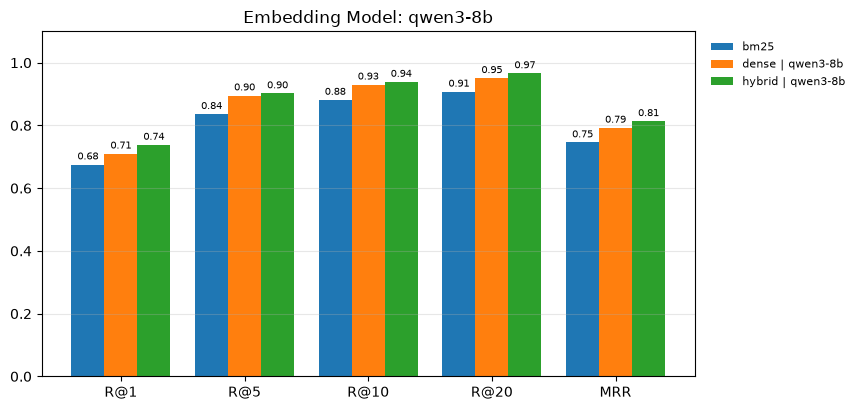


=== bge-m3  (openrouter: baai/bge-m3) ===
Index geladen: indexes\bge-m3


embed the queries:   0%|          | 0/1500 [00:00<?, ?text/s]

dense | bge-m3                   R@1=0.648  R@5=0.819  R@10=0.865  R@20=0.899  MRR=0.727
hybrid | bge-m3                  R@1=0.717  R@5=0.883  R@10=0.929  R@20=0.953  MRR=0.791


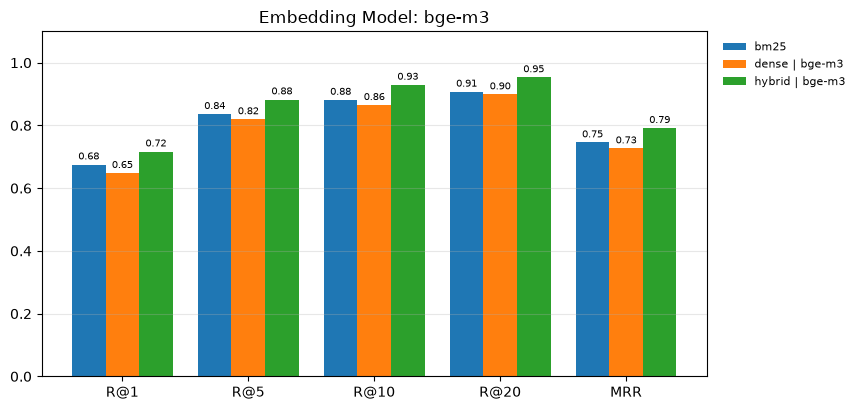


=== voyage-4-large  (openrouter: voyageai/voyage-4-large) ===
Index geladen: indexes\voyage-4-large


embed the queries:   0%|          | 0/1500 [00:00<?, ?text/s]

dense | voyage-4-large           R@1=0.721  R@5=0.915  R@10=0.951  R@20=0.970  MRR=0.805
hybrid | voyage-4-large          R@1=0.757  R@5=0.916  R@10=0.949  R@20=0.969  MRR=0.829


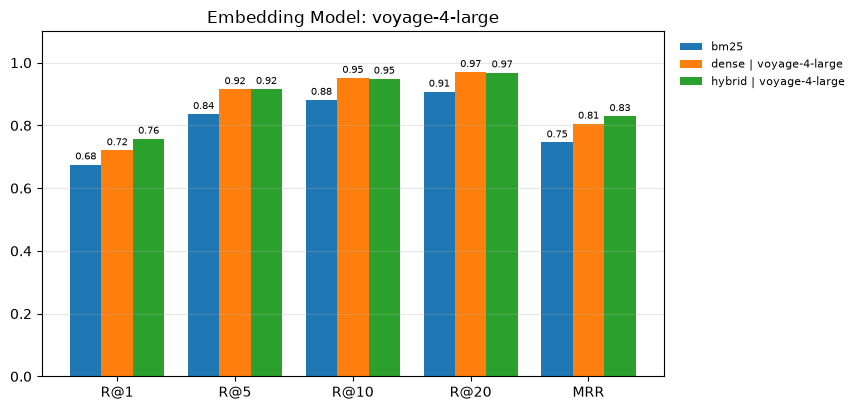


=== oai-3-large  (openrouter: openai/text-embedding-3-large) ===
Index geladen: indexes\oai-3-large


embed the queries:   0%|          | 0/1500 [00:00<?, ?text/s]

dense | oai-3-large              R@1=0.607  R@5=0.835  R@10=0.880  R@20=0.913  MRR=0.704
hybrid | oai-3-large             R@1=0.705  R@5=0.883  R@10=0.925  R@20=0.954  MRR=0.785


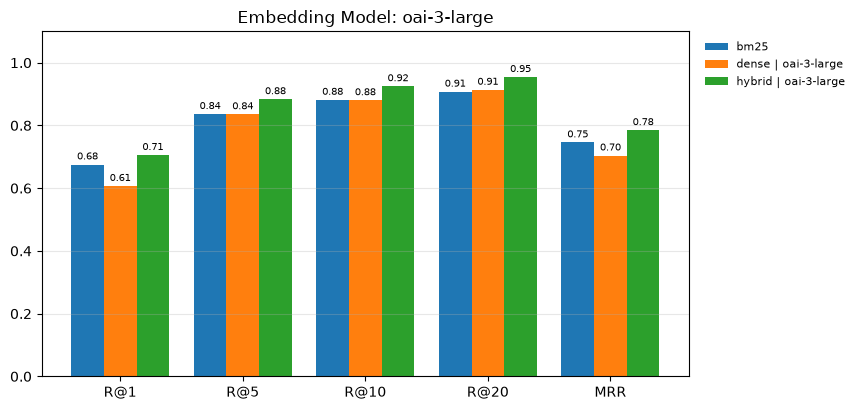


=== qwen3-4b  (openrouter: qwen/qwen3-embedding-4b) ===


Korpus einbetten (qwen3-4b):   0%|          | 0/20958 [00:00<?, ?text/s]

Index gespeichert: indexes\qwen3-4b


embed the queries:   0%|          | 0/1500 [00:00<?, ?text/s]

dense | qwen3-4b                 R@1=0.688  R@5=0.881  R@10=0.921  R@20=0.945  MRR=0.774
hybrid | qwen3-4b                R@1=0.730  R@5=0.901  R@10=0.937  R@20=0.963  MRR=0.805


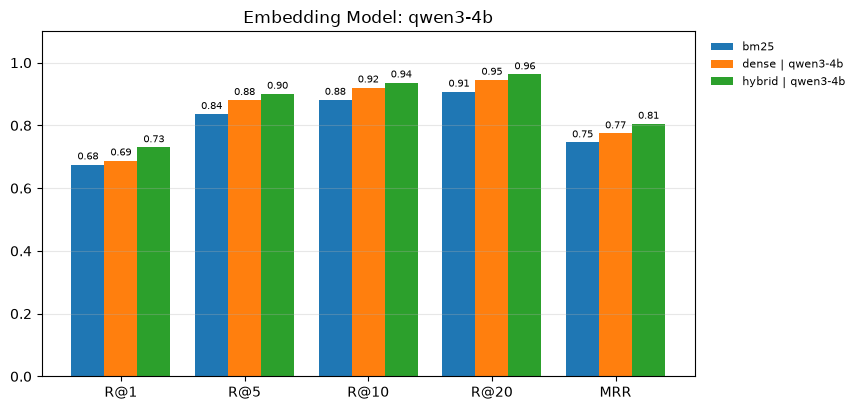

In [ ]:
candidates = {}

for cfg in EMBEDDING_MODELS:
    print(f"\n=== {cfg['name']}  ({cfg['provider']}: {cfg['model']}) ===")
    emb = make_embeddings(cfg)
    vs = load_or_build_index(cfg, emb)
    q_vecs = embed_texts(emb, [cfg.get("query_prefix", "") + q for q in questions],
                         EMBED_BATCH[cfg["provider"]], desc="embed the queries")
    _, dense_ids = vs.index.search(q_vecs, DEPTH)
    hybrid_ids = []
    for bm25_ranking, dense_ranking in zip(bm25_ids, dense_ids):
        fused = rrf([bm25_ranking, dense_ranking], weights=RRF_WEIGHTS)
        hybrid_ids.append(fused[:CAND_DEPTH])
    candidates[cfg["name"]] = hybrid_ids

    model_results = [all_results["bm25"]]
    for method, id_lists in [("dense", dense_ids), ("hybrid", hybrid_ids)]:
        label = f"{method} | {cfg['name']}"
        res, ranks = evaluate(id_lists, label, config={"model": cfg["model"], "rrf_weights": RRF_WEIGHTS})
        all_results[label], all_ranks[label] = res, ranks
        model_results.append(res)

    plot_bars(model_results, f"Embedding Model: {cfg['name']}")
    del vs, emb

The hybrid approach works best for every embedding model in our setting (train split, n = 1,500). The strongest combination is **hybrid Voyage-4-Large with an MRR of 0.829 and Recall@1 of 0.757**, followed by hybrid Qwen3-Embedding-8B (MRR 0.813, Recall@1 0.738). Compared to BM25 alone (MRR 0.746), the best hybrid variant improves MRR by about 11%.

**Recall@20 is high for all hybrid variants (0.953 to 0.969).** The correct paragraph is almost always among the top 20 candidates. The remaining gap is mostly about ranking it at the very top, which is exactly what reranking addresses.

For reranking, we use the hybrid candidates of Qwen3-8B. Their Recall@20 (0.966) is almost identical to Voyage-4-Large (0.969), and since the reranker completely reorders the top 20, this upper bound is what matters (and the Qwen3 embeddings are way cheaper).

## Reranking

Now, to get to some even better numbers for Recall@k with lower k and better MRR we can use Reranking. Here a cross-encoder reads question and paragraph together and outputs a score for how well they fit. This is the most detailed look into questions and paragraphs, but it is also quite expensive. This is why for RAG-like systems Reranking is only used to re-order the best-fitting chunks found by the cheaper methods (embedding, keyword-based or hybrid).

In [ ]:
def openrouter_rerank_one(model, query, documents, retries=5):
    """Rerank a list of documents for a given query using the OpenRouter API."""
    for attempt in range(retries):
        r = requests.post(
            f"{OPENROUTER_BASE}/rerank",
            headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"},
            json={"model": model, "query": query, "documents": documents},
            timeout=60,
        )
        if r.status_code == 200:
            scores = [float("-inf")] * len(documents)
            for item in r.json()["results"]:
                scores[item["index"]] = item["relevance_score"]
            return scores
        if r.status_code in (429, 500, 502, 503, 504):
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
    r.raise_for_status()


def score_openrouter(cfg, cand_lists):
    cache_path = os.path.join(CACHE_ROOT, f"rerank_{cfg['name']}.json")
    cache = {}
    if os.path.exists(cache_path):
        with open(cache_path, encoding="utf-8") as f:
            cache = json.load(f)
    key = lambda qid, cands: f"{qid}|{','.join(map(str, cands))}"
    save = lambda: json.dump(cache, open(cache_path, "w", encoding="utf-8"))

    todo = [(q, c, key(qid, c)) for q, c, qid in zip(questions, cand_lists, qids) if key(qid, c) not in cache]
    print(f"{len(cand_lists) - len(todo)} from Cache, {len(todo)} new Requests to OpenRouter")

    def work(item):
        q, c, k = item
        return k, openrouter_rerank_one(cfg["model"], q, [doc_texts[i] for i in c])

    try:
        with ThreadPoolExecutor(OPENROUTER_WORKERS) as ex:
            futures = [ex.submit(work, t) for t in todo]
            for n, fut in enumerate(tqdm(as_completed(futures), total=len(futures),
                                         desc=f"Rerank ({cfg['name']})", unit="query"), 1):
                k, scores = fut.result()
                cache[k] = scores
                if n % 50 == 0:
                    save()
    finally:
        save()
    return [np.asarray(cache[key(qid, c)]) for qid, c in zip(qids, cand_lists)]


def score_local(cfg, cand_lists):
    from sentence_transformers import CrossEncoder
    ce = CrossEncoder(cfg["model"], max_length=512, device=DEVICE)
    pairs = [(q, doc_texts[i]) for q, cands in zip(questions, cand_lists) for i in cands]
    flat = ce.predict(pairs, batch_size=32, show_progress_bar=True)
    out, pos = [], 0
    for cands in cand_lists:
        out.append(np.asarray(flat[pos:pos + len(cands)]))
        pos += len(cands)
    return out


def score_candidates(cfg, cand_lists):
    if cfg["provider"] == "openrouter":
        return score_openrouter(cfg, cand_lists)
    if cfg["provider"] == "local":
        return score_local(cfg, cand_lists)
    raise ValueError(f"Unknown provider: {cfg['provider']}")


=== Reranker voyage-3-lite  (openrouter: voyageai/rerank-3-lite) ===
0 aus Cache, 10500 neue Requests an OpenRouter


Rerank (voyage-3-lite):   0%|          | 0/10500 [00:00<?, ?query/s]

hybrid | qwen3-8b + voyage-3-lite R@1=0.913  R@5=0.975  R@10=0.978  R@20=0.979  MRR=0.941


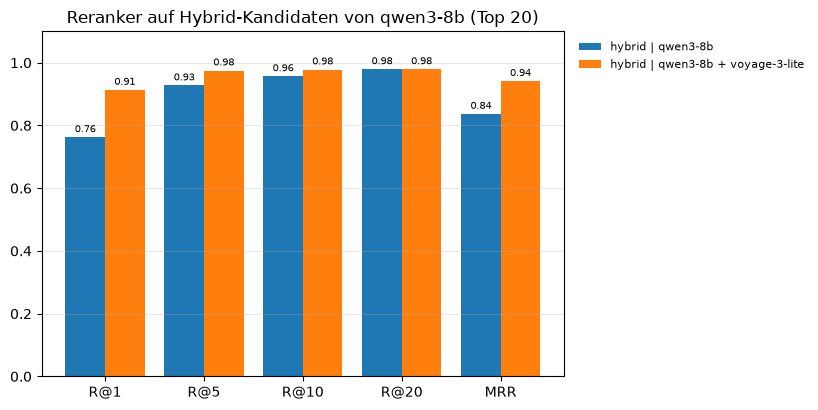

In [ ]:
base_name = RERANK_BASE or EMBEDDING_MODELS[0]["name"]
base_cands = candidates[base_name]
top_lists = [[int(i) for i in c[:TOP_N]] for c in base_cands]

rerank_results = [all_results[f"hybrid | {base_name}"]]
for cfg in RERANKERS:
    print(f"\n=== Reranker {cfg['name']}  ({cfg['provider']}: {cfg['model']}) ===")
    score_lists = score_candidates(cfg, top_lists)

    reranked = []
    for top, rest, scores in zip(top_lists, base_cands, score_lists):
        order = np.argsort(-scores, kind="stable")
        reranked.append([top[j] for j in order] + [int(i) for i in rest[TOP_N:]])

    label = f"hybrid | {base_name} + {cfg['name']}"
    res, ranks = evaluate(reranked, label, config={"reranker": cfg["model"], "top_n": TOP_N})
    all_results[label], all_ranks[label] = res, ranks
    rerank_results.append(res)

plot_bars(rerank_results, f"Reranker on hybrid candidates of {base_name} (Top {TOP_N})")

With reranking it was possible to significantly improve Recall@1, Recall@5 and MRR significantly. **TODO: add percentages**

## Overview

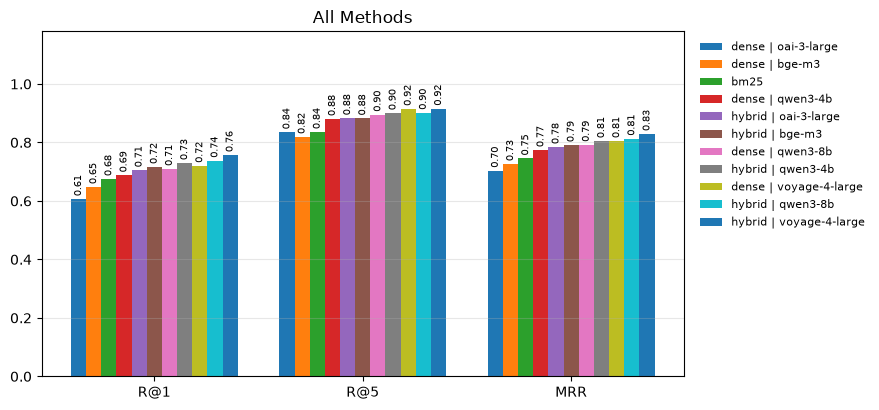

,method,R@1,R@5,R@10,R@20,MRR
0,hybrid | voyage-4-large,0.757,0.916,0.949,0.969,0.829
1,hybrid | qwen3-8b,0.738,0.902,0.939,0.966,0.813
2,dense | voyage-4-large,0.721,0.915,0.951,0.970,0.805
3,hybrid | qwen3-4b,0.730,0.901,0.937,0.963,0.805
4,dense | qwen3-8b,0.710,0.895,0.930,0.951,0.792
5,hybrid | bge-m3,0.717,0.883,0.929,0.953,0.791
6,hybrid | oai-3-large,0.705,0.883,0.925,0.954,0.785
7,dense | qwen3-4b,0.688,0.881,0.921,0.945,0.774
8,bm25,0.675,0.836,0.881,0.907,0.746
9,dense | bge-m3,0.648,0.819,0.865,0.899,0.727


In [ ]:
overview = sorted(all_results.values(), key=lambda r: r[f"mrr@{KMAX}"])
plot_bars(overview, "All Methods", metrics=["recall@1", "recall@5", f"mrr@{KMAX}"])

table = pd.DataFrame([{"method": r["method"],
                       **{f"R@{k}": r[f"recall@{k}"] for k in K_VALUES},
                       "MRR": r[f"mrr@{KMAX}"]} for r in all_results.values()])
table.sort_values("MRR", ascending=False).round(3).reset_index(drop=True)